## Import the Libraries

In [46]:
import re
import string
import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import seaborn as sns
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from wordcloud import WordCloud
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.metrics.pairwise import cosine_similarity
import re
import warnings
warnings.filterwarnings('ignore')

In [2]:
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\vincy\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\vincy\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\vincy\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\vincy\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [3]:
pip install wordcloud

Note: you may need to restart the kernel to use updated packages.


## Load the dataset

In [4]:
df = pd.read_csv("all_upwork_jobs_2024-02-07-2024-03-24.csv")

In [5]:
df.head()

,title,link,published_date,is_hourly,hourly_low,hourly_high,budget,country
0,Experienced Media Buyer For Solar Pannel and R...,https://www.upwork.com/jobs/Experienced-Media-...,2024-02-17 09:09:54+00:00,False,NaN,NaN,500.0,NaN
1,Full Stack Developer,https://www.upwork.com/jobs/Full-Stack-Develop...,2024-02-17 09:09:17+00:00,False,NaN,NaN,1100.0,United States
2,SMMA Bubble App,https://www.upwork.com/jobs/SMMA-Bubble-App_%7...,2024-02-17 09:08:46+00:00,True,10.0,30.0,NaN,United States
3,Talent Hunter Specialized in Marketing,https://www.upwork.com/jobs/Talent-Hunter-Spec...,2024-02-17 09:08:08+00:00,True,NaN,NaN,NaN,United States
4,Data Engineer,https://www.upwork.com/jobs/Data-Engineer_%7E0...,2024-02-17 09:07:42+00:00,False,NaN,NaN,650.0,India


## Preprocess the data 

In [6]:
df.shape

(244828, 8)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244828 entries, 0 to 244827
Data columns (total 8 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   title           244827 non-null  object 
 1   link            244827 non-null  object 
 2   published_date  244828 non-null  object 
 3   is_hourly       244828 non-null  bool   
 4   hourly_low      102422 non-null  float64
 5   hourly_high     98775 non-null   float64
 6   budget          103891 non-null  float64
 7   country         239751 non-null  object 
dtypes: bool(1), float64(3), object(4)
memory usage: 13.3+ MB


In [25]:
df['published_date'] = pd.to_datetime(df['published_date'], errors='coerce')
df['month_year'] = df['published_date'].dt.to_period('M')

In [26]:
df['published_date'].dtypes

datetime64[ns, UTC]

In [10]:
df.isnull().sum()

title                  1
link                   1
published_date         0
is_hourly              0
hourly_low        142406
hourly_high       146053
budget            140937
country             5077
dtype: int64

In [11]:
# fill the missing values
df['country'] = df['country'].fillna('Unknown')

title_mode = df['title'].mode()[0] if not df['title'].mode().empty else ''
df['title'] = df['title'].fillna(title_mode)

link_mode = df['link'].mode()[0] if not df['link'].mode().empty else ''
df['link'] = df['link'].fillna(link_mode)

median_budget = df[df['is_hourly'] == False]['budget'].median()
df['budget'] = df['budget']
df.loc[(df['is_hourly'] == False) & (df['budget'].isnull()), 'budget'] = median_budget
df.loc[df['is_hourly'] == True, 'budget'] = 0.0

median_hourly_low = df[df['is_hourly'] == True]['hourly_low'].median()
median_hourly_high = df[df['is_hourly'] == True]['hourly_high'].median()

df['hourly_low'] = df['hourly_low']
df['hourly_high'] = df['hourly_high']

df.loc[(df['is_hourly'] == True) & (df['hourly_low'].isnull()), 'hourly_low'] = median_hourly_low
df.loc[(df['is_hourly'] == True) & (df['hourly_high'].isnull()), 'hourly_high'] = median_hourly_high

df.loc[df['is_hourly'] == False, ['hourly_low', 'hourly_high']] = 0.0


In [12]:
df.isnull().sum()

title             0
link              0
published_date    0
is_hourly         0
hourly_low        0
hourly_high       0
budget            0
country           0
dtype: int64

In [13]:
df.head()

,title,link,published_date,is_hourly,hourly_low,hourly_high,budget,country
0,Experienced Media Buyer For Solar Pannel and R...,https://www.upwork.com/jobs/Experienced-Media-...,2024-02-17 09:09:54+00:00,False,0.0,0.0,500.0,Unknown
1,Full Stack Developer,https://www.upwork.com/jobs/Full-Stack-Develop...,2024-02-17 09:09:17+00:00,False,0.0,0.0,1100.0,United States
2,SMMA Bubble App,https://www.upwork.com/jobs/SMMA-Bubble-App_%7...,2024-02-17 09:08:46+00:00,True,10.0,30.0,0.0,United States
3,Talent Hunter Specialized in Marketing,https://www.upwork.com/jobs/Talent-Hunter-Spec...,2024-02-17 09:08:08+00:00,True,15.0,30.0,0.0,United States
4,Data Engineer,https://www.upwork.com/jobs/Data-Engineer_%7E0...,2024-02-17 09:07:42+00:00,False,0.0,0.0,650.0,India


In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

# Custom domain-specific stopwords
custom_stopwords = {
    'looking', 'need', 'needed', 'wanted', 'expert', 
    'developer', 'designer', 'project', 'help', 'work'
}
stop_words.update(custom_stopwords)

def preprocess_text(text):
    if not isinstance(text, str):
        return ''
    
    # 1. Lowercasing
    text = text.lower()
    
    # 2. Clean URLs, HTML tags, and non-alphabetical characters
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    
    # 3. Tokenization
    tokens = word_tokenize(text)
    
    # 4. Stopword removal & Lemmatization
    clean_tokens = [
        lemmatizer.lemmatize(token)
        for token in tokens
        if token not in stop_words and len(token) > 2
    ]
    
    return ' '.join(clean_tokens)

# Apply preprocessing
df['clean_title'] = df['title'].apply(preprocess_text)
df[['title', 'clean_title']].head(10)

,title,clean_title
0,Experienced Media Buyer For Solar Pannel and R...,experienced medium buyer solar pannel roofing ...
1,Full Stack Developer,full stack
2,SMMA Bubble App,smma bubble app
3,Talent Hunter Specialized in Marketing,talent hunter specialized marketing
4,Data Engineer,data engineer
5,SEO for Portuguese Psychologist site,seo portuguese psychologist site
6,Want to fix the WordPress Plugin,want fix wordpress plugin
7,need Portuguese writers who can understand and...,portuguese writer understand write portuguese
8,Looker Studio Dashboard for Leadgen and E-Comm...,looker studio dashboard leadgen ecommerce tool...
9,PHP/HTML/CSS WordPress Developer Needed for We...,phphtmlcss wordpress website transformation


In [16]:
df['char_count'] = df['title'].apply(len)
df['word_count'] = df['title'].apply(lambda x: len(str(x).split()))
df['clean_word_count'] = df['clean_title'].apply(lambda x: len(str(x).split()))

In [17]:
df.head()

,title,link,published_date,is_hourly,hourly_low,hourly_high,budget,country,clean_title,char_count,word_count,clean_word_count
0,Experienced Media Buyer For Solar Pannel and R...,https://www.upwork.com/jobs/Experienced-Media-...,2024-02-17 09:09:54+00:00,False,0.0,0.0,500.0,Unknown,experienced medium buyer solar pannel roofing ...,76,10,8
1,Full Stack Developer,https://www.upwork.com/jobs/Full-Stack-Develop...,2024-02-17 09:09:17+00:00,False,0.0,0.0,1100.0,United States,full stack,20,3,2
2,SMMA Bubble App,https://www.upwork.com/jobs/SMMA-Bubble-App_%7...,2024-02-17 09:08:46+00:00,True,10.0,30.0,0.0,United States,smma bubble app,15,3,3
3,Talent Hunter Specialized in Marketing,https://www.upwork.com/jobs/Talent-Hunter-Spec...,2024-02-17 09:08:08+00:00,True,15.0,30.0,0.0,United States,talent hunter specialized marketing,38,5,4
4,Data Engineer,https://www.upwork.com/jobs/Data-Engineer_%7E0...,2024-02-17 09:07:42+00:00,False,0.0,0.0,650.0,India,data engineer,13,2,2


#  UNIVARIATE ANALYSIS

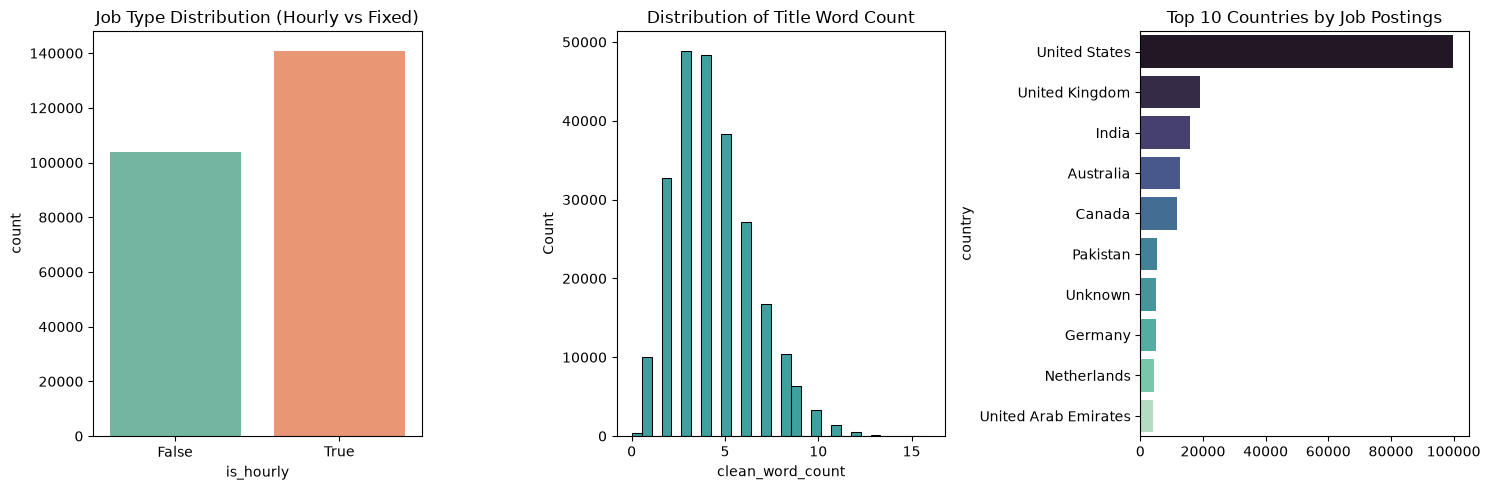

In [18]:
plt.figure(figsize=(15, 5))

# Distribution of Target Variable (is_hourly)
plt.subplot(1, 3, 1)
sns.countplot(x='is_hourly', data=df, palette='Set2')
plt.title('Job Type Distribution (Hourly vs Fixed)')

# Distribution of Clean Word Count
plt.subplot(1, 3, 2)
sns.histplot(df['clean_word_count'], bins=30, color='teal')
plt.title('Distribution of Title Word Count')

# Top 10 Countries posting jobs
plt.subplot(1, 3, 3)
top_countries = df['country'].value_counts().head(10)
sns.barplot(x=top_countries.values, y=top_countries.index, palette='mako')
plt.title('Top 10 Countries by Job Postings')

plt.tight_layout()
plt.show()

#Insights:

1. Job Type Distribution (Hourly vs Fixed)
   
**Hourly jobs are more common:** There are around 140,000 hourly job postings ("True") compared to approximately 104,000 fixed-price job postings ("False").   

**Preference for hourly rate:** Clients post significantly more hourly contracts than fixed-price contracts on this platform. 

2. Distribution of Title Word Count
   
**Short titles are most popular:** Most job posting titles are concise, containing between 3 to 5 words (peaking at around 48,000–49,000 postings). 

**Rarely exceed 10 words:** Titles with more than 8–10 words are very uncommon, and almost no titles exceed 12 words.  

3. Top 10 Countries by Job Postings
   
**United States dominates:** The United States leads by a massive margin, contributing nearly 100,000 job postings.

**Followed by the UK, India, Australia, and Canada:** The United Kingdom and India rank second and third (around 15,000–20,000 postings each), followed closely by Australia and Canada.   

**Other notable contributors:** Pakistan, Germany, the Netherlands, and the United Arab Emirates also make the top 10 list, though with much smaller overall volume.

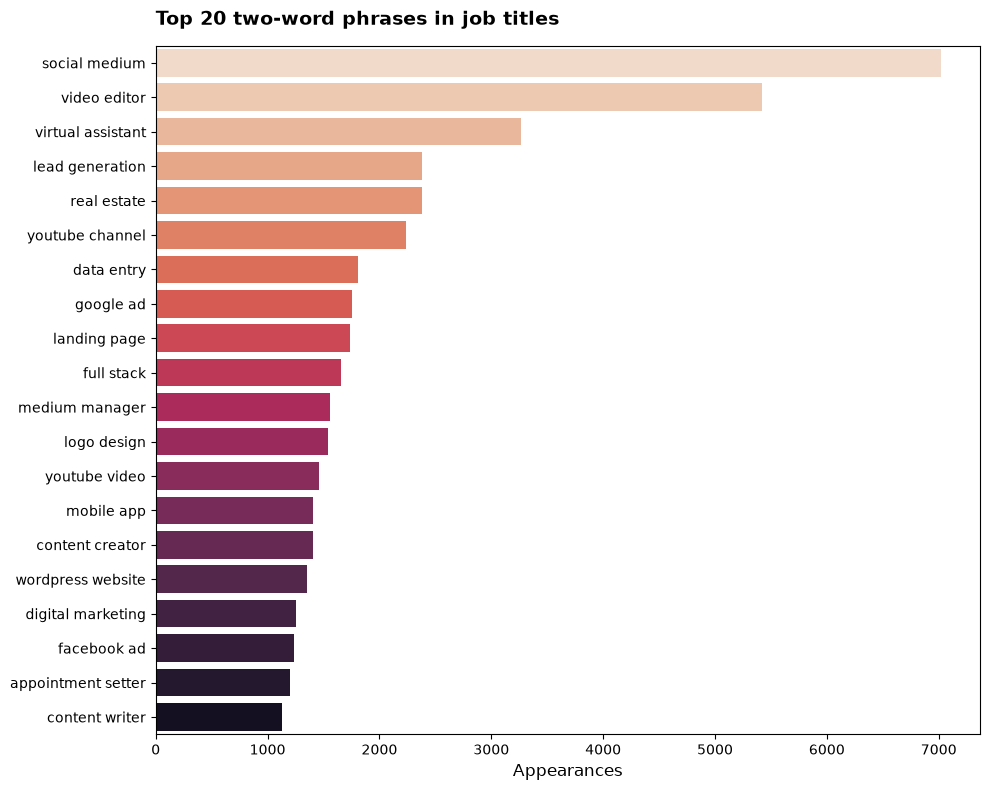

In [19]:
vec = CountVectorizer(ngram_range=(2, 2)).fit(df['clean_title'])
bag_of_words = vec.transform(df['clean_title'])
sum_words = bag_of_words.sum(axis=0)

words_freq = [
    (word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()
]
words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)[:20]

bigram_df = pd.DataFrame(words_freq, columns=['Ngram', 'Count'])
plt.figure(figsize=(10, 8))
palette = sns.color_palette('rocket_r', n_colors=20)

ax = sns.barplot(
    x='Count', y='Ngram', data=bigram_df, palette=palette, hue='Ngram', legend=False
)
plt.title(
    'Top 20 two-word phrases in job titles',
    fontsize=14,
    fontweight='bold',
    loc='left',
    pad=15,
)
plt.xlabel('Appearances', fontsize=12)
plt.ylabel('', fontsize=12)
plt.tight_layout()
plt.show()

#Insights:

"Social medium" (media) is the clear leader: It is by far the most requested two-word phrase in job titles, appearing over 7,000 times.  

High demand for video creation & virtual assistance:"Video editor" ranks 2nd with around 5,400 appearances.   

"Virtual assistant" comes in 3rd with over 3,200 appearances.   

Marketing & sales lead generation are top priorities: Phrases like "lead generation," "google ad," "landing page," "digital marketing," and "facebook ad" all feature heavily in job listings.   

Real estate & YouTube content are popular niches:"Real estate" and "youtube channel" both appear over 2,000 times.   

"Youtube video" also ranks high with around 1,400 appearances.   

Technical & administrative skills remain steady: Roles such as "data entry," "full stack," "logo design," "mobile app," "wordpress website," and "content writer" show strong, consistent demand ranging between 1,000 and 1,800 appearances.

# BIVARIATE ANALYSIS

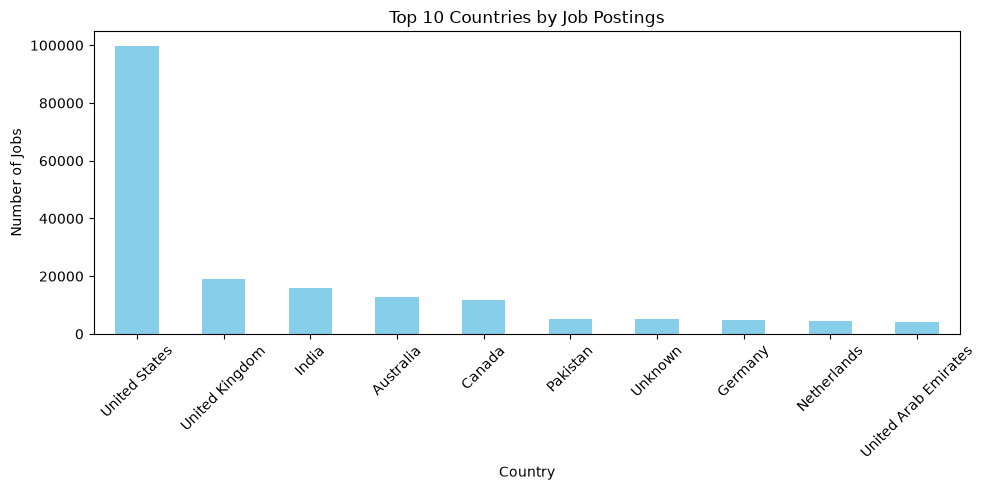

In [27]:
plt.figure(figsize=(10, 5))
df['country'].value_counts().head(10).plot(kind='bar', color='skyblue')
plt.title('Top 10 Countries by Job Postings')
plt.xlabel('Country')
plt.ylabel('Number of Jobs')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#Insights:

**United States dominates the market:** The US is by far the largest source of job postings, reaching nearly 100,000 jobs—significantly higher than all other countries combined.   

**Strong secondary market:** The United Kingdom ranks 2nd with around 19,000 jobs.  

Australia (around 13,000 jobs) and Canada (around 12,000 jobs) also feature in the top 5.  

**India is the top Asian market:** India holds the 3rd spot overall with approximately 16,000 job postings.  

**Lower volume among remaining top countries:** Pakistan, Germany, the Netherlands, and the United Arab Emirates each contribute between 4,000 and 5,000 jobs.   

A small portion of postings (around 5,000) have an "Unknown" location.

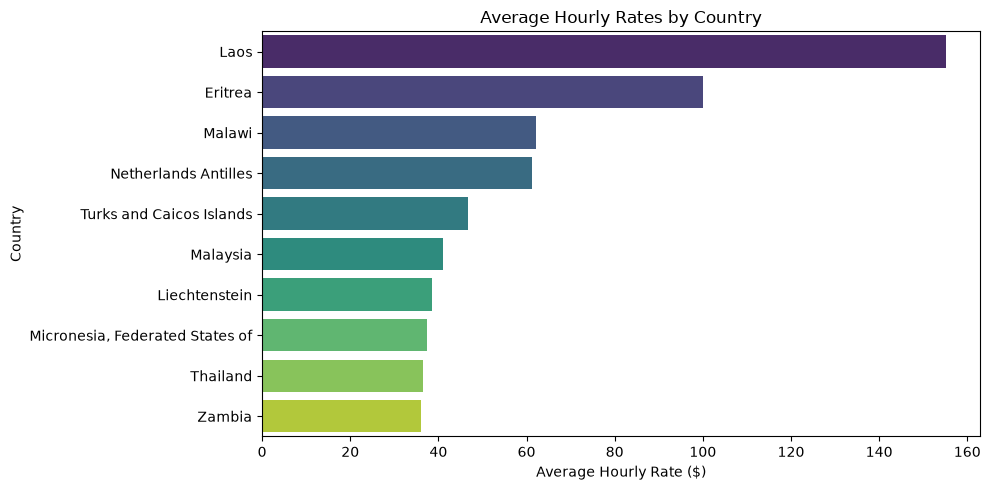

In [31]:
df_hourly = df[(df['is_hourly'] == True) & (df['hourly_high'] > 0)].copy()
df_hourly['avg_hourly'] = (df_hourly['hourly_low'] + df_hourly['hourly_high']) / 2
country_rates = df_hourly.groupby('country')['avg_hourly'].mean().reset_index()
top_countries = country_rates.sort_values(by='avg_hourly', ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x='avg_hourly', y='country', data=top_countries, palette='viridis', hue='country', legend=False)
plt.title('Average Hourly Rates by Country')
plt.xlabel('Average Hourly Rate ($)')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

#Insights:

**Laos leads by a wide margin:** Laos has the highest average hourly rate on this list, sitting at over $150 per hour. 

**Eritrea and Malawi follow:** Eritrea ranks second with an average near $100 per hour, followed by Malawi and the Netherlands Antilles at around 60 per hour.   

**Mid-tier countries hover around $40–50:** Nations like Turks and Caicos Islands, Malaysia, Liechtenstein, and Micronesia have average rates ranging between 40 and 48 per hour.   

**Thailand and Zambia are on the lower end:** Thailand and Zambia record the lowest average rates shown, both resting just under $40 per hour.

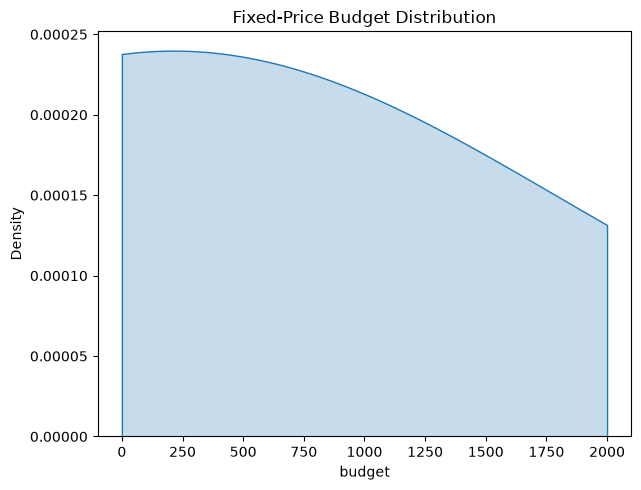

In [20]:
plt.figure(figsize=(12, 5))
# Budget distribution by job type
plt.subplot(1, 2, 2)
sns.kdeplot(data=df[df['is_hourly'] == False], x='budget', clip=(0, 2000), label='Fixed-Price', fill=True)
plt.title('Fixed-Price Budget Distribution')

plt.tight_layout()
plt.show()

#Insights:

**Most jobs are budgeted under $500:** The highest concentration (density) of fixed-price jobs occurs at lower budget amounts, peaking between 0 and 300.

**Higher budgets are less common:** As the budget amount increases past 500, the density steadily drops, meaning high-budget jobs ($1,500 to 2,000) are posted far less frequently.   

**Budget range capped in view:** The chart focuses on fixed-price projects capped at $2,000, with a broad mix of small to mid-sized projects overall. 

# MULTIVARIATE ANALYSIS

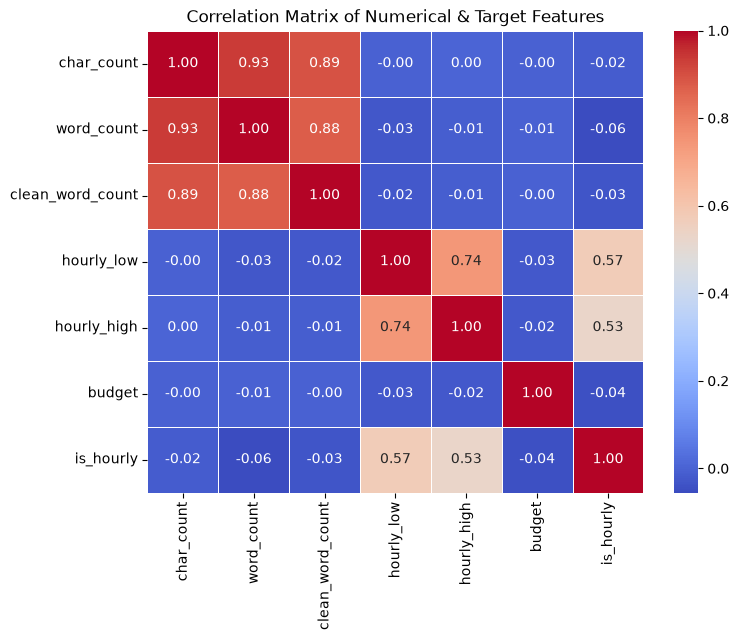

In [21]:
plt.figure(figsize=(8, 6))

# Correlation matrix of numerical variables
numeric_cols = ['char_count', 'word_count', 'clean_word_count', 'hourly_low', 'hourly_high', 'budget', 'is_hourly']
corr_matrix = df[numeric_cols].corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix of Numerical & Target Features')
plt.show()

#Insights:

**Text length features are strongly tied together:** Character count (char_count), word count (word_count), and clean word count (clean_word_count) have very high positive correlations (between 0.88 and 0.93). Longer titles naturally have higher character and word counts.   

**Hourly rates move together:** The low hourly rate (hourly_low) and high hourly rate (hourly_high) show a strong positive correlation (0.74), meaning job posts with higher minimum rates also tend to offer higher maximum rates.   

**Hourly status links to hourly rates:** Whether a job is hourly (is_hourly) shows a moderate positive correlation with both hourly_low (0.57) and hourly_high (0.53).   

**Text length has zero effect on job pricing:** Title length (char_count or word_count) has practically no correlation (near 0.00) with hourly_low, hourly_high, or budget. The length of a title does not impact job pay.   

**Fixed budget is independent of other features:** Fixed-price budget has virtually no correlation (near -0.01 to -0.04) with text length metrics or hourly pricing features. 

# Train the model

In [53]:
df_salary = df[(df['is_hourly'] == False) & (df['budget'] > 0)].copy()
tfidf = TfidfVectorizer(max_features=1000, stop_words='english')
X = tfidf.fit_transform(df_salary['clean_title'])
y = df_salary['budget']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = RidgeCV(alphas=[0.1, 1.0, 10.0, 100.0])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(f"Budget Prediction R2 Score: {r2_score(y_test, y_pred):.4f}")

Budget Prediction R2 Score: 0.0063


In [54]:
tfidf_rec = TfidfVectorizer(max_features=3000, stop_words='english')
tfidf_matrix = tfidf_rec.fit_transform(df['clean_title'])

def recommend_jobs(job_title_query, top_n=5):
    query_vec = tfidf_rec.transform([preprocess_text(job_title_query)])
    similarity = cosine_similarity(query_vec, tfidf_matrix).flatten()
    top_indices = similarity.argsort()[::-1][:top_n]
    return df.iloc[top_indices][['title', 'country', 'budget', 'hourly_low', 'hourly_high', 'link']]

In [56]:
print("\nSample Recommendations for 'Python Developer':")
print(recommend_jobs('Python developer', 5))


Sample Recommendations for 'Python Developer':
                                 title         country  budget  hourly_low  \
244341  Looking For a Python developer   United States   430.0         0.0   
235261                Python Developer           India     0.0        15.0   
25331                 Python developer  United Kingdom     0.0        16.0   
182514                Python Developer   United States     0.0         8.0   
201501  Looking For a Python developer   United States   270.0         0.0   

        hourly_high                                               link  
244341          0.0  https://www.upwork.com/jobs/Looking-For-Python...  
235261         30.0  https://www.upwork.com/jobs/Python-Developer_%...  
25331          44.0  https://www.upwork.com/jobs/Python-developer_%...  
182514         15.0  https://www.upwork.com/jobs/Python-Developer_%...  
201501          0.0  https://www.upwork.com/jobs/Looking-For-Python...  
